# 06 Seq2Seq英译法：数据准备与GRU编解码器

本篇对应 **day06**，保存在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。承接05的注意力计算，开始搭建英文到法文的Seq2Seq案例：让成对文本经过清洗、词表、Dataset、DataLoader，再进入GRU编码器与两种解码器。

主资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码`1234`。已核对`03-视频/day06`的**16节文件名**，在线阅读《07-案例Seq2Seq英译法案例.pdf》全部63页，重点核对本日对应的第1–40页与模型图。视频未逐段转录，未取得课程原代码、原语料和本地PDF。

沿用前篇：**全部为Markdown单元；Python代码块按顺序复制到代码单元即可运行；8幅图以Notebook attachments内嵌，不依赖其他图片文件。** 本篇12条英法句对独立编写，验证数据和模型接口以及一次参数更新，不把随机预测当作翻译成绩。完整训练与生成评估属于后续学习内容。

| day06视频 | 内容 | 本篇重点 |
| --- | --- | --- |
| 01 | 英译法需求 | 序列映射与逐token分类 |
| 02–04 | CUDA配置与测试 | 驱动、PyTorch构建与实际运算检查 |
| 05–08 | 清洗、预处理、Dataset、DataLoader | 双词表、EOS、PAD、变长批次 |
| 09–10 | GRU编码器与测试 | embedding、memory、hidden与packing |
| 11–13 | 无注意力解码器 | 上一步token与隐藏状态怎样传递 |
| 14–16 | 带注意力解码器 | 课件固定位置版与逐键加性版 |

学习主线：`英文/法文句对 → 规范化 → 分开建词表 → token IDs → padded batch → Encoder → Decoder → 法语词表logits`。

## 1. 案例目标：每步预测法语词，整体生成序列

输入一句英文，输出一句法文，两侧长度可以不同。模型学习的是句子级条件生成，不是把每个英文词独立查字典替换。

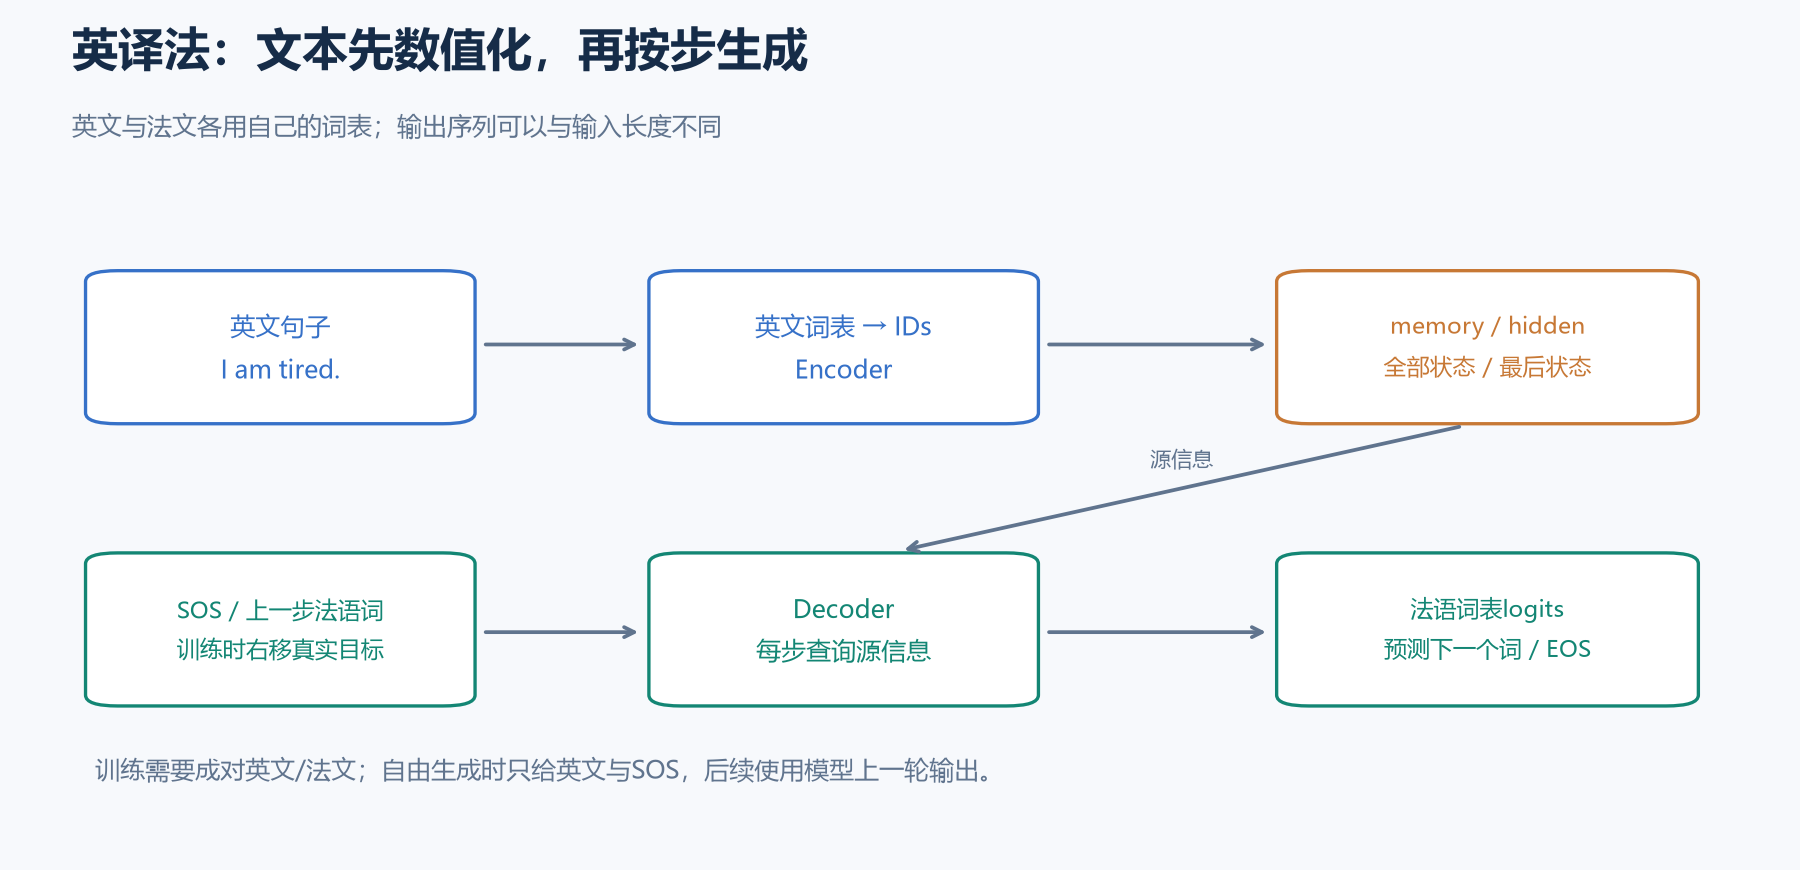

对源序列$x$与目标序列$y=(y_1,…,y_T)$，常见自回归建模为：

$$P(y\mid x)=\prod_{t=1}^{T}P(y_t\mid y_{<t},x).$$

每个时间步是目标词表上的分类，整个任务是序列生成。EOS也是一个要预测的目标token。课件说明原语料有10599条句对，英语词表2803、法语词表4345；这些是**课件给出的统计**，本篇没有读取原语料重新计算，示例词表也不沿用这些数字。

## 2. CUDA环境：分清四件事

CUDA是NVIDIA GPU计算体系。阅读本篇和运行小样例可以使用CPU；只有准备做GPU训练时，才需要配置相应环境。

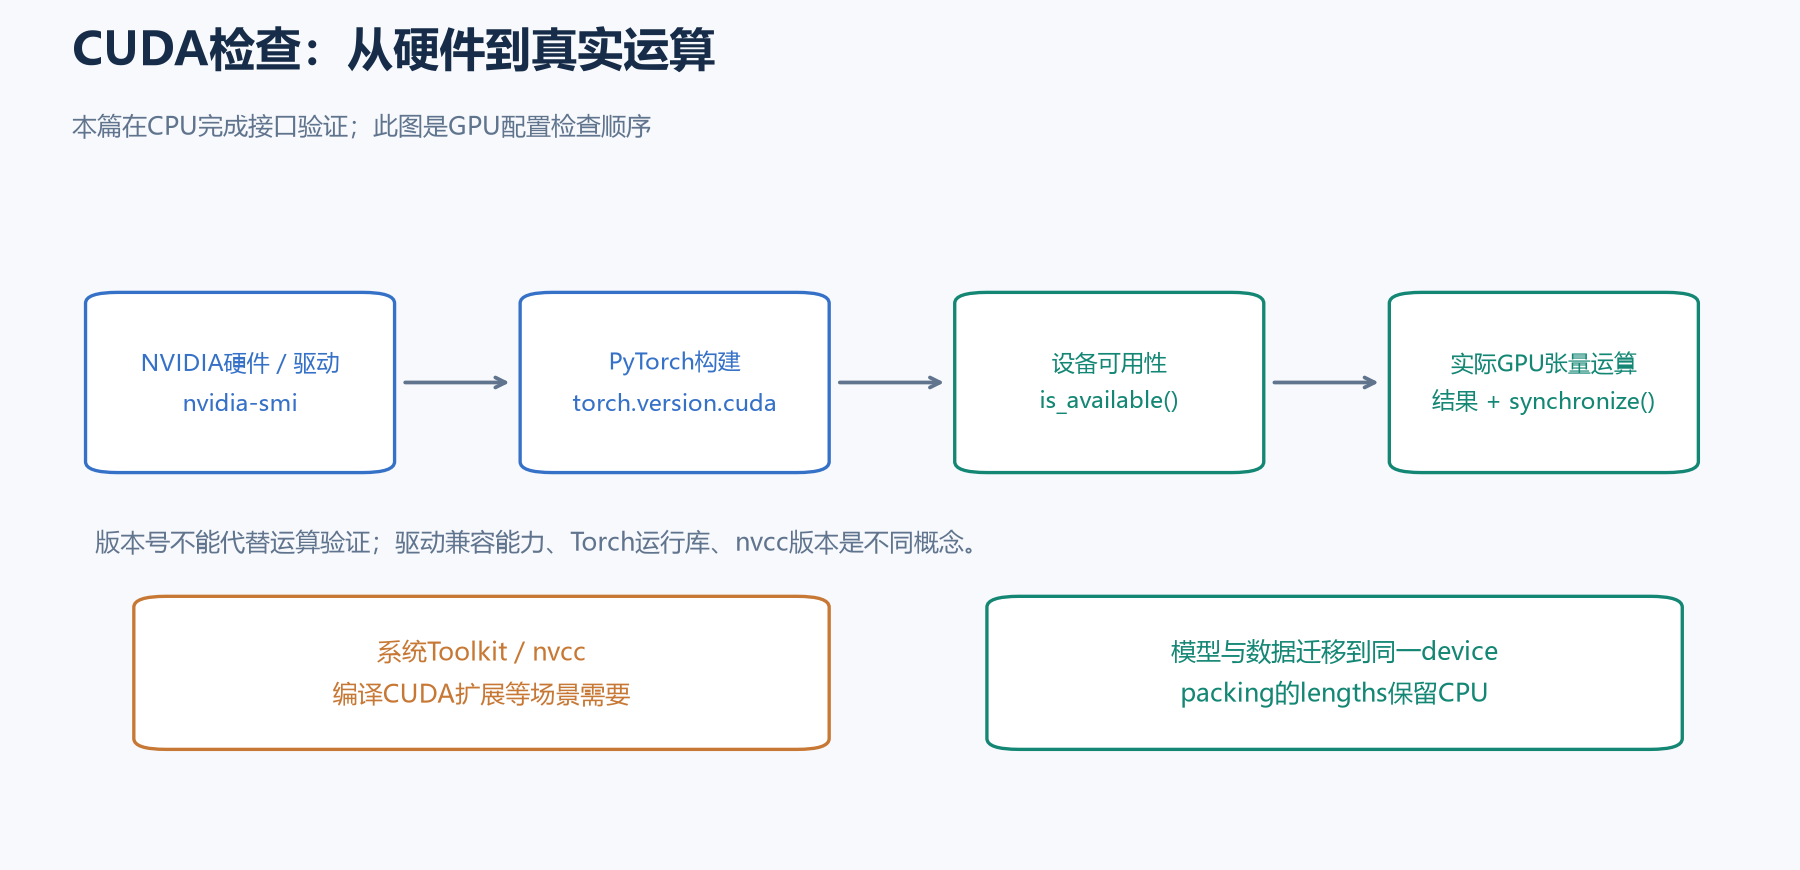

| 层次 | 作用 | 常见检查 |
| --- | --- | --- |
| NVIDIA硬件与驱动 | 让系统与GPU通信 | `nvidia-smi`查看GPU与驱动 |
| PyTorch安装构建 | CPU版或包含CUDA支持的构建 | `torch.__version__`、`torch.version.cuda` |
| 实际可用设备 | 当前进程是否能调用GPU | `torch.cuda.is_available()` |
| 模型与张量位置 | 参与同一运算的数据在同一设备 | `model.to(device)`、`tensor.to(device)` |

`nvidia-smi`显示的“CUDA Version”表示驱动支持能力，不是证明当前Python已安装该CUDA版PyTorch。`nvcc --version`检查本机CUDA Toolkit编译器，也不能替代PyTorch运算测试。

预编译PyTorch包通常带有所需CUDA运行库或对应依赖；使用它运行常规模型，通常不必另外安装完整Toolkit。编译自定义CUDA扩展等场景才需要相应编译环境。驱动兼容性、Python版本、显卡计算能力和PyTorch支持范围仍要核对。

安装时使用[PyTorch官方选择器](https://pytorch.org/get-started/locally/)选择系统、Python包和计算平台，执行它当前给出的命令，不照抄视频中的旧版本号。官方页面已用于核对安装路径；本篇没有在用户的系统环境中安装或验证CUDA。

## 3. 可运行环境与设备自检

本篇代码只依赖NumPy与PyTorch，样例句对直接写在笔记中。安装示例是CPU构建；需要GPU时改用官方选择器生成的CUDA构建命令。

```bash
python -m pip install numpy
python -m pip install torch --index-url https://download.pytorch.org/whl/cpu
```

```python
import io
import math
import platform
import re
import unicodedata
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

SEED = 2026
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")  # 为复查数值，本篇样例固定在CPU运行
print("Python", platform.python_version(), "NumPy", np.__version__, "PyTorch", torch.__version__)
print("PyTorch CUDA构建:", torch.version.cuda, "当前CUDA可用:", torch.cuda.is_available())
if torch.cuda.is_available():
    probe = torch.arange(4, dtype=torch.float32, device="cuda")
    torch.testing.assert_close((probe * probe).cpu(), torch.tensor([0., 1., 4., 9.]))
    torch.cuda.synchronize()
    print("GPU实际运算通过:", torch.cuda.get_device_name(0))
else:
    print("本次未运行GPU分支；后续样例使用CPU")
```

GPU训练时模型与浮点/索引张量一起迁移；packing的lengths通常保留在CPU。只写`device=...`不会自动迁移已经创建的模型和数据。GPU分支是可运行的自检示例，本篇验证环境为CPU，不能据此断言其他机器GPU可用。

## 4. 原始数据：一行一对，TAB分隔

课件使用`eng-fra-v2.txt`：每行两列，英文在前、法文在后，中间是制表符`\t`。空格属于句子内部，不能拿`split()`切整行来判断两列。

本篇自编数据共有12对。前8对用于训练接口，后2对作为dev、再后2对作为test；本篇不计算dev/test翻译成绩。训练词表只从前8对建立，留出样本用于演示未知词如何处理。

```python
RAW_TSV = """Go!\tVa !
I am cold.\tJ'ai froid.
I am tired.\tJe suis fatigué.
He is calm.\tIl est calme.
She is ready.\tElle est prête.
We are here.\tNous sommes ici.
Thank you.\tMerci.
They are late.\tIls sont en retard.
I am ready.\tJe suis prêt.
We are tired.\tNous sommes fatigués.
You are here.\tTu es ici.
She is calm.\tElle est calme.
"""

def read_tsv(text):
    pairs = []
    for line_number, line in enumerate(io.StringIO(text), start=1):
        if not line.strip():
            continue
        fields = line.rstrip("\r\n").split("\t")
        if len(fields) != 2 or any(not field.strip() for field in fields):
            raise ValueError(f"第{line_number}行应有两列非空文本，使用TAB分隔")
        pairs.append((fields[0].strip(), fields[1].strip()))
    if not pairs:
        raise ValueError("没有可用句对")
    return pairs

raw_pairs = read_tsv(RAW_TSV)
assert len(raw_pairs) == 12
for malformed in ("hello bonjour", "a\tb\tc", "a\t "):
    try:
        read_tsv(malformed)
    except ValueError:
        pass
    else:
        raise AssertionError("损坏行不应被静默接受")
print("句对数:", len(raw_pairs), "第一对:", raw_pairs[0])
```

若读真实文件，可用`Path(...).read_text(encoding="utf-8")`再交给该函数；不要为了凑成两列而悄悄截去第三列。若其他数据源有合法第三列，需要单独定义其格式。

## 5. 文本清洗：保留法语重音和词内撇号

课件先小写、为`.!?`分词，再用ASCII字母正则排除其他字符。这种入门简化会删掉`é/ê/ç`等法语字母，也会改变缩约形式。它不是通用的法语清洗规则。

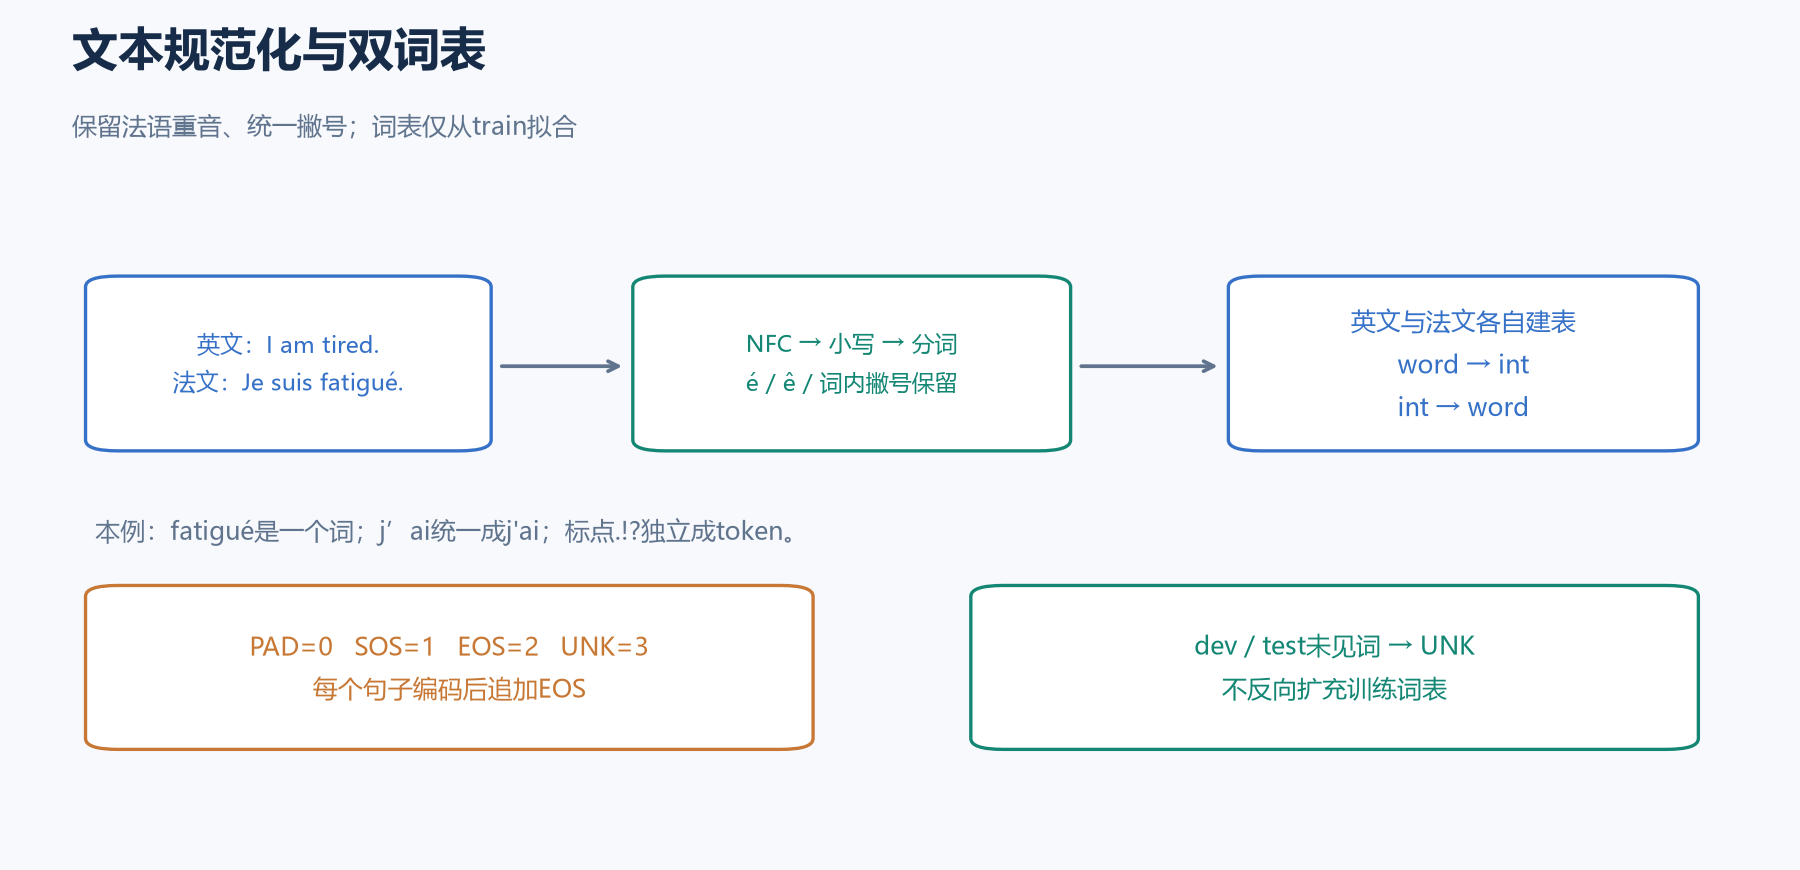

本篇使用Unicode NFC统一组合形式、小写、统一弯撇号，再提取字母词及`.!?`，保留词内撇号。数字和其他符号未纳入这个教学分词器；真实翻译语料需要根据任务处理数字、姓名、连字符和更广的标点，不能无限删除。

```python
TOKEN_RE = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)*|[.!?]", re.UNICODE)

def normalize_tokens(text):
    normalized = unicodedata.normalize("NFC", text).lower().replace("’", "'")
    tokens = TOKEN_RE.findall(normalized)
    if not tokens:
        raise ValueError("规范化后文本为空")
    return tokens

assert normalize_tokens("  J’ai froid!  ") == ["j'ai", "froid", "!"]
assert normalize_tokens("Elle est prête.") == ["elle", "est", "prête", "."]
assert normalize_tokens("fatigue\u0301") == normalize_tokens("fatigué")
assert normalize_tokens("I   am\n tired.") == ["i", "am", "tired", "."]
assert normalize_tokens("Go!") == ["go", "!"]
print("保留重音:", normalize_tokens("Je suis fatigué."))
print("保留词内撇号:", normalize_tokens("J’ai froid."))
```

清洗后使用tokens列表，不反复对带尾部空格的字符串做`split(' ')`；后者可能得到空token。训练、验证、预测必须使用同一个规范化函数。

## 6. 长度、去重与划分：先处理句对再建词表

源端和目标端各自检查长度。下面把`MAX_TOKENS=10`明确定义为**包含EOS后的最大长度**；不是10个正文词再偷偷增加一个EOS。

同一源句可以有多条合法译文，不应把它们当作损坏数据；但划分时应让相同规范化源句进入同一集合，避免看到同一句英文的译文泄漏到验证/测试。本篇源句互不重复，人工固定划分仅用于演示接口。

```python
MAX_TOKENS = 10
normalized_pairs = []
seen_pairs = set()
for source, target in raw_pairs:
    src_tokens, tgt_tokens = normalize_tokens(source), normalize_tokens(target)
    if len(src_tokens) + 1 > MAX_TOKENS or len(tgt_tokens) + 1 > MAX_TOKENS:
        raise ValueError("示例句对超过包含EOS的长度上限")
    key = (tuple(src_tokens), tuple(tgt_tokens))
    if key not in seen_pairs:
        normalized_pairs.append((src_tokens, tgt_tokens))
        seen_pairs.add(key)

train_pairs = normalized_pairs[:8]
dev_pairs = normalized_pairs[8:10]
test_pairs = normalized_pairs[10:12]
source_groups = [{tuple(src) for src, _ in split} for split in (train_pairs, dev_pairs, test_pairs)]
assert all(source_groups[i].isdisjoint(source_groups[j])
           for i in range(3) for j in range(i + 1, 3))
assert len(train_pairs) + len(dev_pairs) + len(test_pairs) == 12
print("train/dev/test:", [len(x) for x in (train_pairs, dev_pairs, test_pairs)])
```

真实大语料一般按规范化源句分组，固定随机种子划分，再仅从train建词表；另检查近重复、模板和来源重叠。本篇12句不能提供可信的翻译泛化评估。

## 7. 两个词表与四个特殊token

英文词表和法文词表分别建立。相同数字在两侧通常指不同词；英文ID不能直接当法文ID。Embedding接收整数索引，并从其自己的表中读取可训练向量，这与预训练Word2Vec算法不是同一件事。

| 本篇ID | token | 作用 |
| --- | --- | --- |
| 0 | `<PAD>` | 对齐batch内长度 |
| 1 | `<SOS>` | decoder的首个输入 |
| 2 | `<EOS>` | 源句终点、目标生成终点 |
| 3 | `<UNK>` | 训练词表外的词 |

课件使用SOS=0、EOS=1；本篇增加PAD/UNK并重新编号，**不与课件权重直接兼容**。模型、数据、词表和checkpoint必须保持一致的编号与词表顺序。

```python
PAD, SOS, EOS, UNK = 0, 1, 2, 3
SPECIALS = ["<PAD>", "<SOS>", "<EOS>", "<UNK>"]

class Vocabulary:
    def __init__(self, token_sequences):
        words = sorted({word for tokens in token_sequences for word in tokens})
        self.idx2word = SPECIALS + words
        self.word2idx = {word: index for index, word in enumerate(self.idx2word)}
        assert len(self.word2idx) == len(self.idx2word)

    def __len__(self):
        return len(self.idx2word)

    def encode(self, tokens):
        return torch.tensor([self.word2idx.get(word, UNK) for word in tokens] + [EOS],
                            dtype=torch.long)

    def decode(self, ids):
        return [self.idx2word[int(index)] for index in ids]

src_vocab = Vocabulary(src for src, _ in train_pairs)
tgt_vocab = Vocabulary(tgt for _, tgt in train_pairs)
for vocab in (src_vocab, tgt_vocab):
    assert vocab.idx2word[:4] == SPECIALS
    assert all(vocab.idx2word[index] == word for word, index in vocab.word2idx.items())
    assert vocab.encode(["词表外示例"]).tolist() == [UNK, EOS]
assert "prêt" not in tgt_vocab.word2idx
assert "prête" in tgt_vocab.word2idx
print("英语词表:", len(src_vocab), "法语词表:", len(tgt_vocab))
print("目标重音词:", [w for w in tgt_vocab.idx2word if "é" in w or "ê" in w])
print("dev未知词:", tgt_vocab.decode(tgt_vocab.encode(dev_pairs[0][1])))
```

词表只由train建，因此dev中的`prêt`会成为UNK；训练中的`prête`保留重音。不能为了消除验证集UNK，再用验证/测试数据扩充训练词表。更大任务可选子词分词器，但也要明确其训练数据来源。

## 8. Dataset：返回CPU上的变长long张量

每个样本返回源序列和目标序列，均追加EOS，不在Dataset里把整个数据集提前搬到GPU。这样方便变长拼批和DataLoader worker使用，设备迁移放在取出batch之后。

```python
class TranslationDataset(Dataset):
    def __init__(self, pairs, source_vocab, target_vocab):
        self.items = [(source_vocab.encode(src), target_vocab.encode(tgt)) for src, tgt in pairs]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        if not 0 <= index < len(self.items):
            raise IndexError("样本索引越界")
        source, target = self.items[index]
        return source.clone(), target.clone()

train_dataset = TranslationDataset(train_pairs, src_vocab, tgt_vocab)
dev_dataset = TranslationDataset(dev_pairs, src_vocab, tgt_vocab)
test_dataset = TranslationDataset(test_pairs, src_vocab, tgt_vocab)
first_source, first_target = train_dataset[0]
assert first_source.ndim == first_target.ndim == 1
assert first_source.dtype == first_target.dtype == torch.long
assert first_source.device.type == "cpu"
assert first_source[-1].item() == first_target[-1].item() == EOS
for bad_index in (-1, len(train_dataset)):
    try:
        train_dataset[bad_index]
    except IndexError:
        pass
    else:
        raise AssertionError("越界索引不能静默夹到首尾样本")
print("首条源IDs:", first_source.tolist(), "目标IDs:", first_target.tolist())
```

课件把越界索引夹在合法范围内，容易隐藏调用错误；本篇明确报错。Dataset返回clone，避免外部修改示例张量污染内部缓存。

## 9. collate_fn：把不同长度放进同一batch

默认DataLoader会尝试stack，各样本长度不同就无法直接stack。课件`batch_size=1`避开了这个问题，但改成更大的batch需要自定义拼批：源与目标分别右PAD，并保留真实长度。

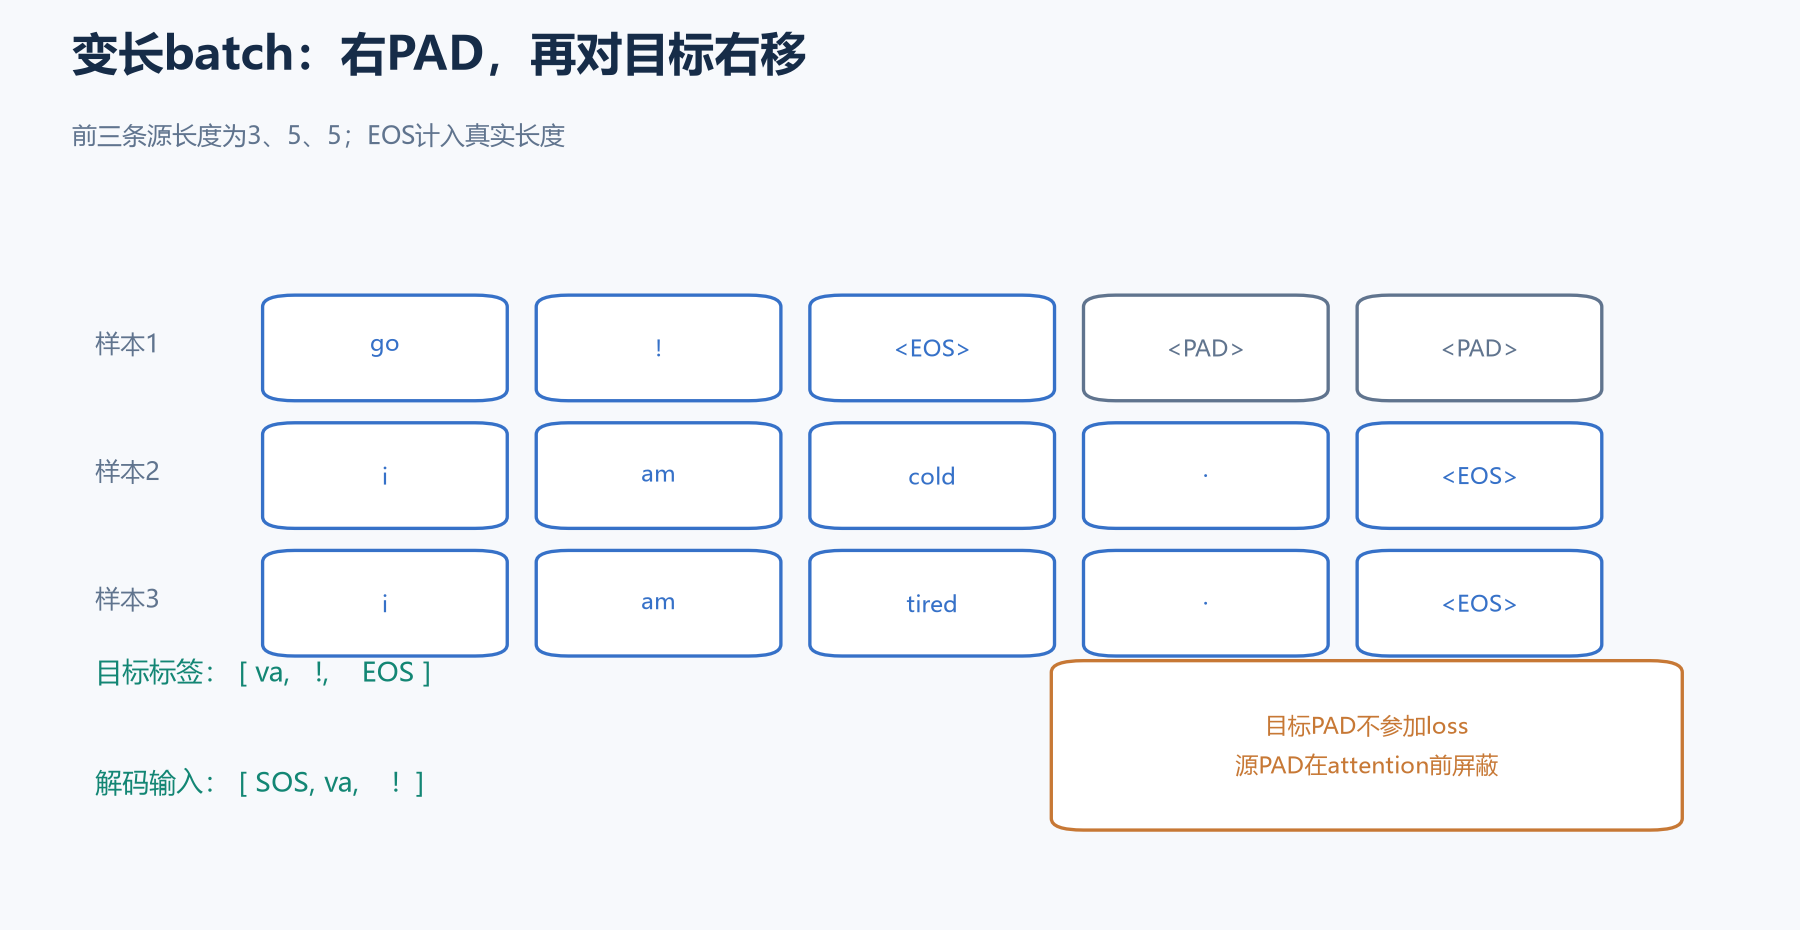

```python
def collate_translation(items):
    sources, targets = zip(*items)
    source_lengths = torch.tensor([len(x) for x in sources], dtype=torch.long)
    target_lengths = torch.tensor([len(y) for y in targets], dtype=torch.long)
    source = pad_sequence(sources, batch_first=True, padding_value=PAD)
    target = pad_sequence(targets, batch_first=True, padding_value=PAD)
    source_valid = torch.arange(source.shape[1])[None, :] < source_lengths[:, None]
    target_valid = torch.arange(target.shape[1])[None, :] < target_lengths[:, None]
    return {"source":source, "target":target, "source_lengths":source_lengths,
            "target_lengths":target_lengths, "source_valid":source_valid,
            "target_valid":target_valid}

loader = DataLoader(train_dataset, batch_size=3, shuffle=False, num_workers=0,
                    collate_fn=collate_translation)
batch = next(iter(loader))
assert batch["source"].shape == (3, 5)
assert batch["source_lengths"].tolist() == [3, 5, 5]
assert torch.all(batch["source"][~batch["source_valid"]] == PAD)
assert torch.all(batch["target"][~batch["target_valid"]] == PAD)
for i, (src, tgt) in enumerate([train_dataset[j] for j in range(3)]):
    torch.testing.assert_close(batch["source"][i, :len(src)], src)
    torch.testing.assert_close(batch["target"][i, :len(tgt)], tgt)
    assert batch["source"][i, len(src)-1] == EOS
    assert batch["target"][i, len(tgt)-1] == EOS
all_batches = list(loader)
assert sum(len(b["source"]) for b in all_batches) == 8
assert [len(b["source"]) for b in all_batches] == [3, 3, 2]
print("源batch:\n", batch["source"], "真实长度:", batch["source_lengths"].tolist())
print("目标batch:\n", batch["target"], "尾批保留:", [len(b["source"]) for b in all_batches])
```

训练可设置`shuffle=True`和固定的Generator种子。Windows/Notebook教学样例用`num_workers=0`，先把接口跑通；真实训练再测worker、pin_memory和吞吐。`drop_last=True`会丢尾批，不能无意中遗漏样本。

## 10. 目标右移：SOS作为输入，EOS作为标签

若目标是`[va, !, EOS]`，decoder输入应是`[SOS, va, !]`，每步分别预测`[va, !, EOS]`。若把当前位置真实词同时当输入和预测标签，模型会看到答案，不能作为正确自回归训练。

```python
def shift_target_right(target):
    if target.ndim != 2 or target.shape[1] == 0:
        raise ValueError("target必须为非空二维张量")
    shifted = torch.full_like(target, PAD)
    shifted[:, 0] = SOS
    shifted[:, 1:] = target[:, :-1]
    return shifted

decoder_input = shift_target_right(batch["target"])
assert torch.all(decoder_input[:, 0] == SOS)
torch.testing.assert_close(decoder_input[:, 1:], batch["target"][:, :-1])
assert decoder_input[0, :3].tolist() == [SOS] + first_target[:-1].tolist()
print("首条teacher-forcing输入:", tgt_vocab.decode(decoder_input[0, :3]))
print("首条预测标签:", tgt_vocab.decode(batch["target"][0, :3]))
```

全PAD区域的预测不会用于损失；较短样本在EOS标签之后，右移输入可能出现EOS，这不影响有效目标位置。源端EOS可以参与注意力，源端PAD应屏蔽。SOS/EOS的语义与PAD不同。

## 11. GRU编码器：全部状态memory与最后状态hidden

采用单层、单向、batch-first GRU：

| 张量 | shape | 用途 |
| --- | --- | --- |
| source IDs | `(B,S)` | 源词表索引，long |
| embedding | `(B,S,E)` | 可训练词向量 |
| memory | `(B,S,H)` | 每个源位置的上下文表示，供attention读取 |
| hidden | `(1,B,H)` | 每条源序列最后有效状态，用于初始化decoder |

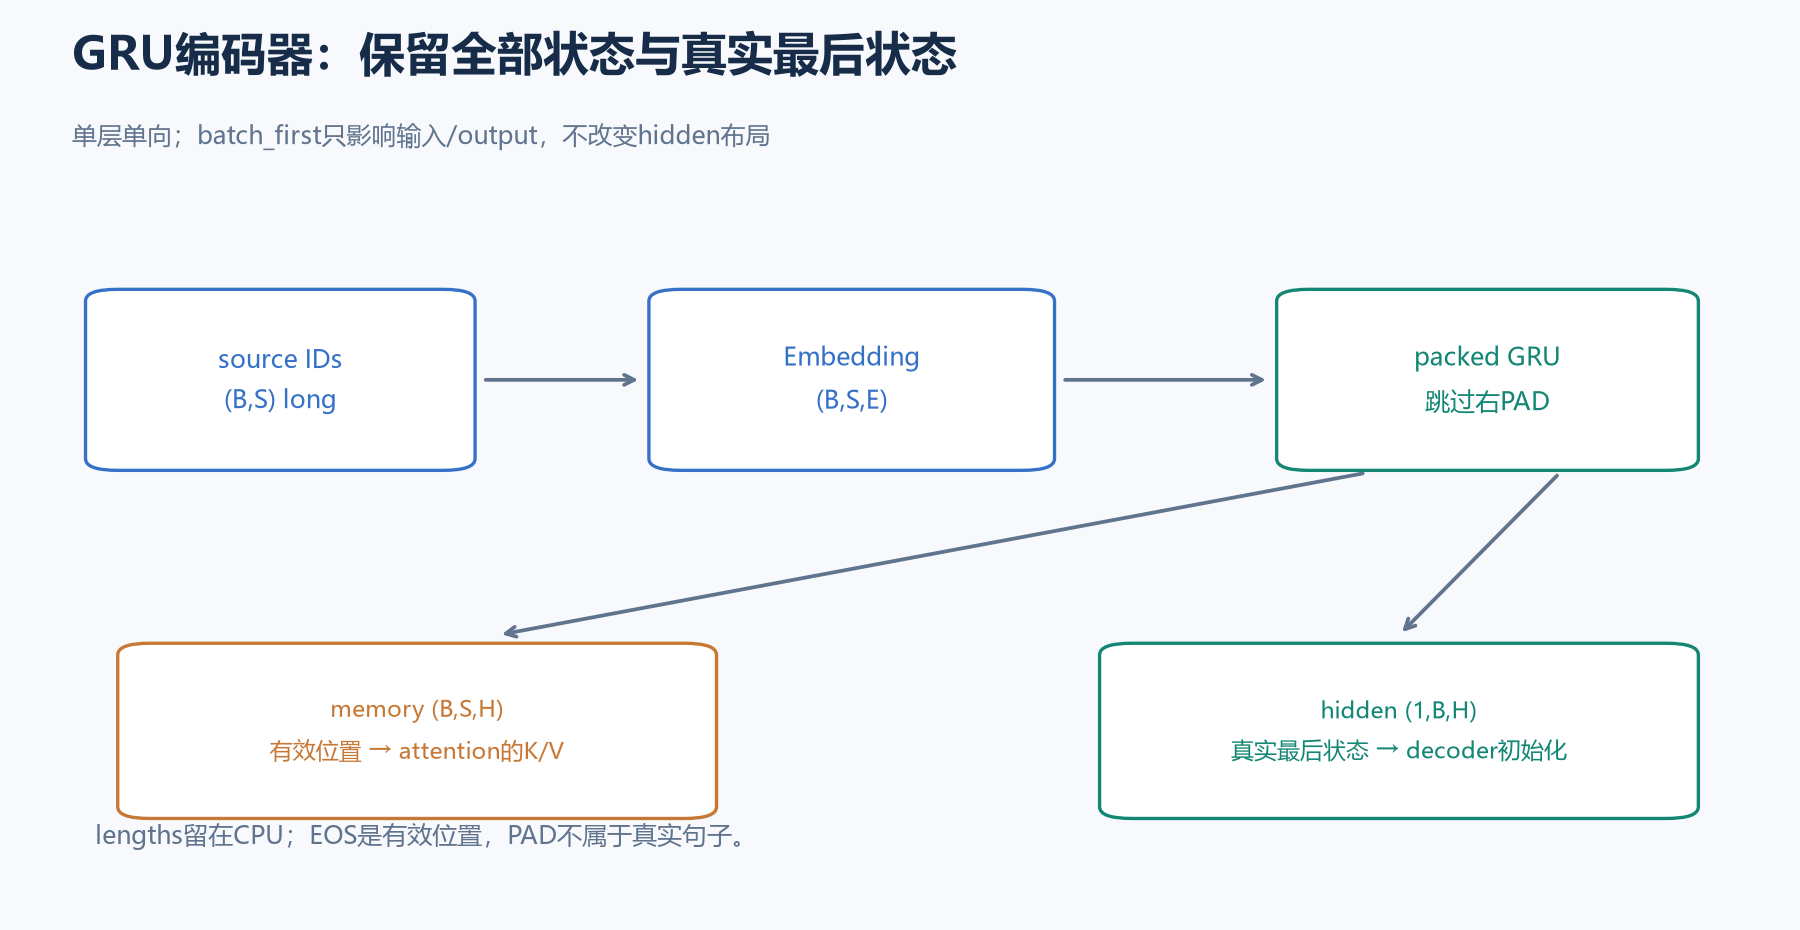

`batch_first=True`只改变输入和output的布局，**hidden仍是`(层数×方向数,B,H)`**。本篇让编码器和解码器H相同；若H不同、双向或多层，需要明确桥接投影与层/方向合并方式。

零PAD向量经过GRU也可能继续改变隐藏状态，因此不应把`memory[:,-1]`当作所有样本的真实最后状态。使用packing跳过右PAD，或按真实长度提取有效状态。

## 12. 可运行的批量GRU编码器

```python
class GRUEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.hidden_dim = hidden_dim

    def forward(self, source, lengths):
        if source.ndim != 2 or source.dtype != torch.long:
            raise ValueError("source应为二维long张量")
        if lengths.ndim != 1 or len(lengths) != len(source) or lengths.device.type != "cpu":
            raise ValueError("lengths应为CPU上的一维batch长度")
        if lengths.dtype != torch.long or (lengths <= 0).any() or (lengths > source.shape[1]).any():
            raise ValueError("lengths必须是合法正整数")
        positions = torch.arange(source.shape[1], device=source.device)[None, :]
        valid = positions < lengths.to(source.device)[:, None]
        if (source[~valid] != PAD).any() or (source[valid] == PAD).any():
            raise ValueError("source需按lengths右PAD，有效区不能包含PAD")
        embedded = self.embedding(source)
        packed = pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        packed_memory, hidden = self.gru(packed)
        memory, recovered_lengths = pad_packed_sequence(
            packed_memory, batch_first=True, total_length=source.shape[1])
        assert torch.equal(recovered_lengths, lengths)
        return memory, hidden

torch.manual_seed(SEED)
EMBED_DIM, HIDDEN_DIM = 12, 16
encoder = GRUEncoder(len(src_vocab), EMBED_DIM, HIDDEN_DIM).to(DEVICE)
source = batch["source"].to(DEVICE)
target = batch["target"].to(DEVICE)
lengths = batch["source_lengths"]
source_valid = batch["source_valid"].to(DEVICE)
memory, hidden = encoder(source, lengths)
assert memory.shape == (3, 5, HIDDEN_DIM)
assert hidden.shape == (1, 3, HIDDEN_DIM)
assert torch.all(memory[~source_valid] == 0)
for i, length in enumerate(lengths.tolist()):
    torch.testing.assert_close(hidden[0, i], memory[i, length-1])
print("编码memory:", tuple(memory.shape), "最后hidden:", tuple(hidden.shape))
```

GRU未显式传初始hidden时默认零状态，等价于本配置的`zeros(1,B,H)`。不能把每个batch上一次的hidden随意传给新句对，否则会串样本历史。

## 13. 编码器验证：批量、逐条与逐时间步一致

课件比较一次输入整句和逐步输入。这里进一步检查：packed batch与逐条无PAD相同，增加右PAD不会改变有效memory和最后hidden。

```python
encoder.eval()
with torch.no_grad():
    batch_memory, batch_hidden = encoder(source, lengths)
    encoder_max_error = 0.0
    for i, length in enumerate(lengths.tolist()):
        ids = source[i:i+1, :length]
        single_memory, single_hidden = encoder(ids, torch.tensor([length]))
        torch.testing.assert_close(single_memory[0], batch_memory[i, :length], atol=1e-6, rtol=1e-5)
        torch.testing.assert_close(single_hidden[:, 0], batch_hidden[:, i], atol=1e-6, rtol=1e-5)
        step_hidden = torch.zeros(1, 1, HIDDEN_DIM)
        step_outputs = []
        for position in range(length):
            step_out, step_hidden = encoder.gru(encoder.embedding(ids[:, position:position+1]), step_hidden)
            step_outputs.append(step_out)
        step_memory = torch.cat(step_outputs, dim=1)
        torch.testing.assert_close(step_memory, single_memory, atol=1e-6, rtol=1e-5)
        torch.testing.assert_close(step_hidden, single_hidden, atol=1e-6, rtol=1e-5)
        encoder_max_error = max(encoder_max_error, (step_memory-single_memory).abs().max().item())
    extra_source = F.pad(source, (0, 3), value=PAD)
    extra_memory, extra_hidden = encoder(extra_source, lengths)
    torch.testing.assert_close(extra_memory[:, :source.shape[1]], batch_memory)
    torch.testing.assert_close(extra_hidden, batch_hidden)
print("整句/逐步最大误差:", encoder_max_error, "额外右PAD不改变有效输出")
```

等价检查的条件是同一参数、相同输入顺序、相同初始状态。带dropout的多层模型应先`eval()`，否则不同前向可能使用不同随机mask。

## 14. 无Attention解码器：状态传递与法语词表输出

普通解码器每一步接收上一目标token，embedding后经过GRU，再投影到法语词表。第一步hidden从encoder取得，第一步token为SOS。

```python
class PlainGRUDecoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, previous_tokens, hidden):
        if previous_tokens.ndim != 2 or previous_tokens.dtype != torch.long:
            raise ValueError("previous_tokens应为(B,T)的long张量")
        embedded = F.relu(self.embedding(previous_tokens))  # 沿用课件的ReLU示例
        features, next_hidden = self.gru(embedded, hidden)
        return self.output(features), next_hidden

plain_decoder = PlainGRUDecoder(len(tgt_vocab), EMBED_DIM, HIDDEN_DIM).to(DEVICE)
start_tokens = torch.full((len(source), 1), SOS, dtype=torch.long, device=DEVICE)
plain_logits, plain_hidden = plain_decoder(start_tokens, hidden)
assert plain_logits.shape == (3, 1, len(tgt_vocab))
assert plain_hidden.shape == (1, 3, HIDDEN_DIM)
assert torch.isfinite(plain_logits).all()
print("普通解码器logits:", tuple(plain_logits.shape))
```

ReLU是这个教学网络的设计选择，会将负激活置零；它本身不能保证防止过拟合。课件`output[0]`只保留第一个batch，本篇保留`(B,T,V_target)`，单步要取时间维时用`logits[:,0]`。

## 15. logits、LogSoftmax与损失必须配对

课件解码器返回LogSoftmax，再接NLLLoss；本篇返回原始logits，接CrossEntropyLoss。LogSoftmax给的是**对数概率**，不是普通概率。

$$\operatorname{CE}(\ell,y)=\operatorname{NLL}(\operatorname{logsoftmax}(\ell),y).$$

```python
first_labels = target[:, 0]
single_step_logits = plain_logits[:, 0]
ce_loss = F.cross_entropy(single_step_logits, first_labels)
log_probs = F.log_softmax(single_step_logits, dim=-1)
nll_loss = F.nll_loss(log_probs, first_labels)
torch.testing.assert_close(ce_loss, nll_loss)
torch.testing.assert_close(log_probs.exp().sum(-1), torch.ones(len(source)))
print("CE/NLL一致:", ce_loss.item())
```

不要先把logits转普通Softmax概率再交给CrossEntropyLoss。目标标签是词ID的long张量；标签是英文还是法文，必须由对应任务确定。

## 16. 课件Attention解码器：固定10个源位置

课件结构是：目标embedding与上一decoder hidden拼接，`Linear(2H,MAX_LENGTH)`直接生成固定位置分数；Softmax后加权全部encoder输出，再与embedding融合、ReLU、GRU和词表投影。

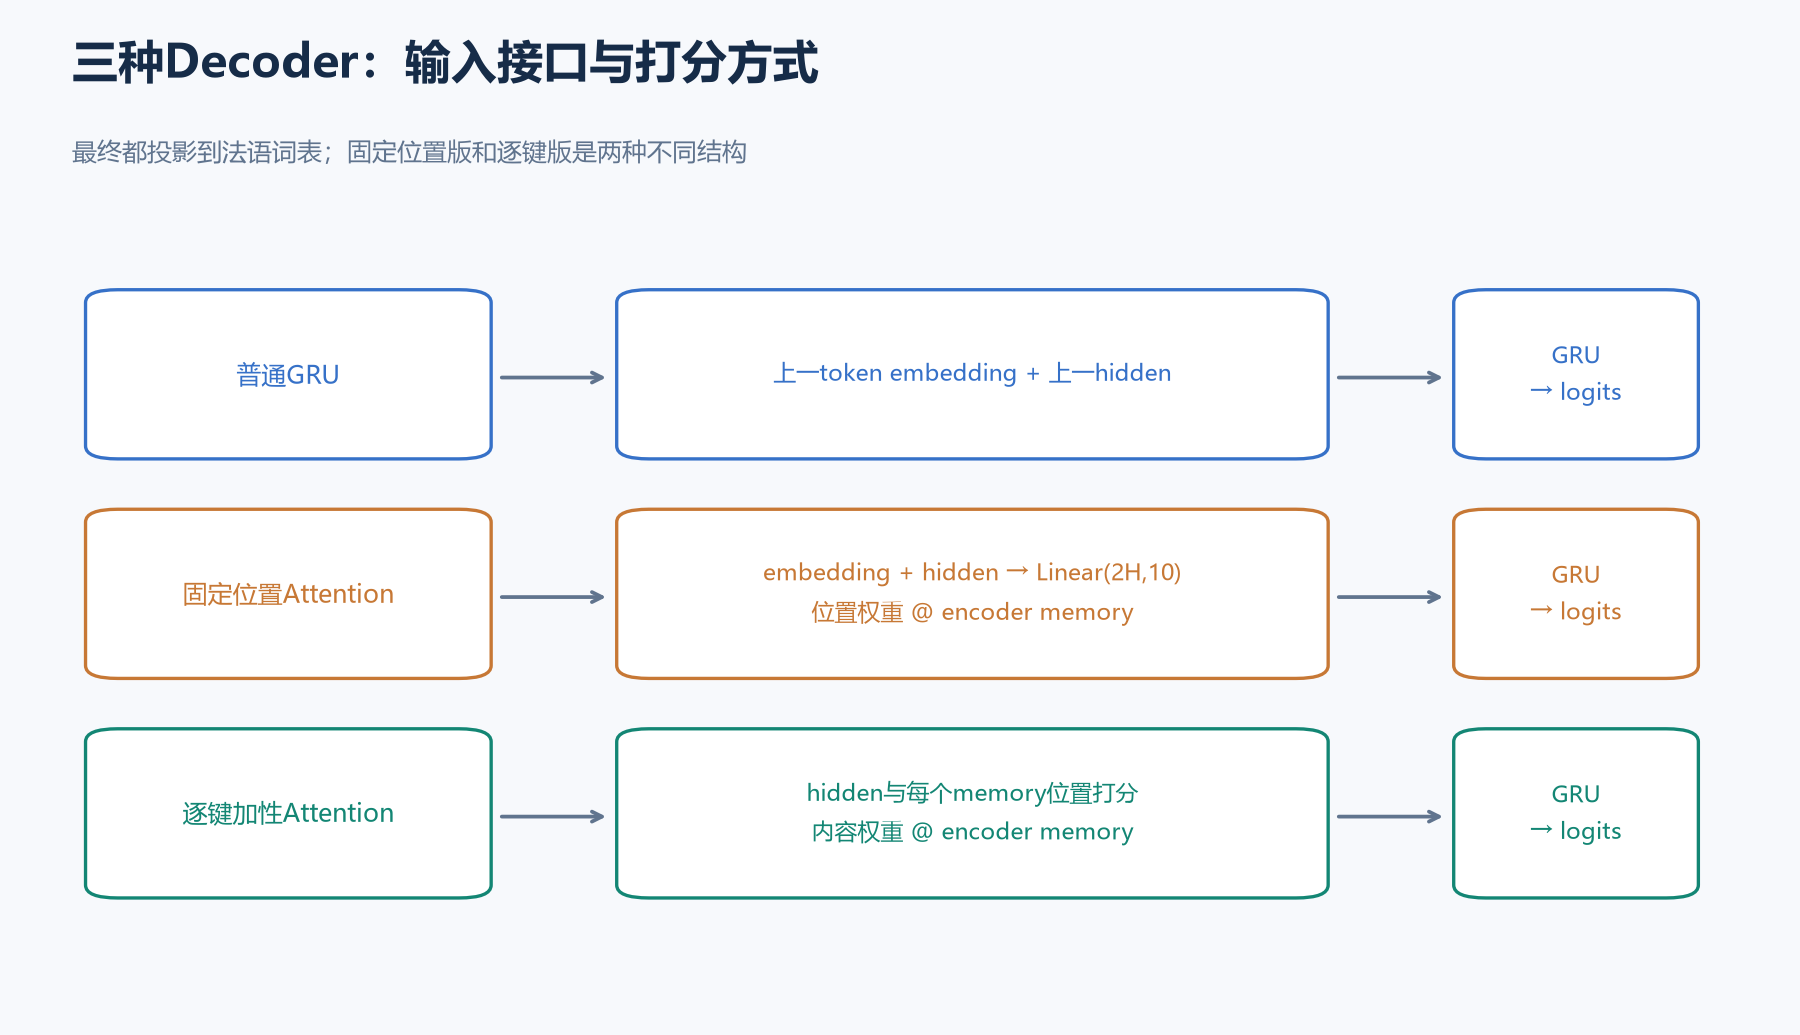

课件称Q为当前目标embedding、K为上一decoder hidden、V为encoder全部位置。这里K是一份状态，**不是每个源位置的内容键**。这个固定位置设计与05中的MyAtt一致，MAX_LENGTH写入输出层，不能直接用于任意新源长度。

另外，零填充encoder_outputs不会自动消除无效位置权重，仍需mask。课件中的`unsqueeze(0)`、`Q[0]`在batch=1时可工作；推广到batch>1要明确轴的位置。

## 17. 固定位置Attention解码器的批量版

下面保留课件“先融合，再GRU”的结构，补上batch接口、PAD mask和超长拒绝。输出原始logits以配合本篇CE。

```python
class FixedAttentionGRUDecoder(nn.Module):
    def __init__(self, vocab_size, hidden_dim, source_slots=10, dropout=0.1):
        super().__init__()
        self.source_slots = source_slots
        self.embedding = nn.Embedding(vocab_size, hidden_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.attn = nn.Linear(2 * hidden_dim, source_slots)
        self.combine = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, previous_tokens, hidden, memory, key_valid):
        if previous_tokens.ndim != 2 or previous_tokens.shape[1] != 1:
            raise ValueError("此解码器一次处理一个时间步")
        B, S, H = memory.shape
        if S > self.source_slots:
            raise ValueError("源长度超过固定位置层的配置")
        if hidden.shape != (1, B, H) or previous_tokens.shape[0] != B:
            raise ValueError("hidden/token/memory的batch或特征不一致")
        if key_valid.dtype != torch.bool or key_valid.shape != (B, S):
            raise ValueError("key_valid应为(B,S)的bool张量")
        if not key_valid.any(-1).all():
            raise ValueError("每条源序列至少有一个有效位置")
        q = self.dropout(self.embedding(previous_tokens))[:, 0]
        scores = self.attn(torch.cat([q, hidden[0]], dim=-1))
        padded_memory = F.pad(memory, (0, 0, 0, self.source_slots-S))
        valid = F.pad(key_valid, (0, self.source_slots-S), value=False)
        weights = scores.masked_fill(~valid, -torch.inf).softmax(-1)
        context = torch.bmm(weights[:, None, :], padded_memory)[:, 0]
        fused = F.relu(self.combine(torch.cat([q, context], dim=-1)))[:, None, :]
        decoded, next_hidden = self.gru(fused, hidden)
        return self.output(decoded), next_hidden, weights

fixed_decoder = FixedAttentionGRUDecoder(len(tgt_vocab), HIDDEN_DIM, source_slots=10).to(DEVICE)
fixed_decoder.eval()
fixed_logits, fixed_hidden, fixed_weights = fixed_decoder(start_tokens, hidden, memory, source_valid)
assert fixed_logits.shape == (3, 1, len(tgt_vocab))
assert fixed_weights.shape == (3, 10)
full_valid = F.pad(source_valid, (0, 10-source.shape[1]), value=False)
assert torch.all(fixed_weights[~full_valid] == 0)
torch.testing.assert_close(fixed_weights.sum(-1), torch.ones(3))
try:
    fixed_decoder(start_tokens, hidden, torch.zeros(3, 11, HIDDEN_DIM),
                  torch.ones(3, 11, dtype=torch.bool))
except ValueError:
    print("已明确拒绝超过固定位置数的输入")
else:
    raise AssertionError("不能默默截去超长源句")
print("固定位置权重:", tuple(fixed_weights.shape), "PAD权重为0")
```

源句长度检查要包含EOS。若原文已经有10个token，追加EOS后有11个位置，不能继续写入长度10的缓存。增加MAX_LENGTH意味着修改固定位置层配置；旧参数也不再直接匹配。

## 18. 逐键加性Attention：不把源长度写进输出层

与固定位置版对照，逐键版使用上一decoder hidden作为Q、每个encoder状态作为K/V，用同一组参数计算每个位置分数：

$$e_{t,j}=v^\top\tanh(W_qs_{t-1}+W_kh_j+b),\quad
\alpha_{t,:}=\operatorname{softmax}_{j}(e_{t,:}+M),\quad c_t=\sum_j\alpha_{t,j}h_j.$$

Q的来源与课件约定不同，这是明确的结构选择。它仍先拼接目标embedding与context，融合后输入GRU。注意力参数不依赖S，源长度可以变化。

```python
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim, score_dim):
        super().__init__()
        self.query_proj = nn.Linear(hidden_dim, score_dim, bias=False)
        self.key_proj = nn.Linear(hidden_dim, score_dim, bias=True)
        self.score = nn.Linear(score_dim, 1, bias=False)

    def forward(self, query, memory, key_valid):
        if query.ndim != 2 or memory.ndim != 3 or query.shape != (memory.shape[0], memory.shape[2]):
            raise ValueError("query应为(B,H)，memory应为(B,S,H)")
        if key_valid.shape != memory.shape[:2] or key_valid.dtype != torch.bool:
            raise ValueError("key_valid应为(B,S)的bool张量")
        if not key_valid.any(-1).all():
            raise ValueError("没有可读取的源位置")
        scores = self.score(torch.tanh(self.query_proj(query)[:, None, :] +
                                       self.key_proj(memory))).squeeze(-1)
        weights = scores.masked_fill(~key_valid, -torch.inf).softmax(-1)
        context = torch.bmm(weights[:, None, :], memory)[:, 0]
        return context, weights

class AdditiveGRUDecoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, score_dim=12, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.dropout = nn.Dropout(dropout)
        self.attention = AdditiveAttention(hidden_dim, score_dim)
        self.combine = nn.Linear(embedding_dim + hidden_dim, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, previous_tokens, hidden, memory, key_valid):
        if previous_tokens.ndim != 2 or previous_tokens.shape != (memory.shape[0], 1):
            raise ValueError("previous_tokens应为(B,1)，一次处理一个时间步")
        if hidden.shape != (1, memory.shape[0], memory.shape[2]):
            raise ValueError("此实现仅支持单层同H的hidden")
        embedded = self.dropout(self.embedding(previous_tokens))[:, 0]
        context, weights = self.attention(hidden[-1], memory, key_valid)
        fused = F.relu(self.combine(torch.cat([embedded, context], dim=-1)))[:, None, :]
        decoded, next_hidden = self.gru(fused, hidden)
        return self.output(decoded), next_hidden, weights

attention_decoder = AdditiveGRUDecoder(len(tgt_vocab), EMBED_DIM, HIDDEN_DIM).to(DEVICE)
attention_decoder.eval()
attn_logits, attn_hidden, attention_weights = attention_decoder(start_tokens, hidden, memory, source_valid)
assert attn_logits.shape == (3, 1, len(tgt_vocab))
assert attn_hidden.shape == (1, 3, HIDDEN_DIM)
assert attention_weights.shape == (3, 5)
assert torch.all(attention_weights[~source_valid] == 0)
torch.testing.assert_close(attention_weights.sum(-1), torch.ones(3))
print("逐键注意力:", tuple(attention_weights.shape), "法语logits:", tuple(attn_logits.shape))
```

输入来源与打分函数决定了这份实现的QKV含义，不能仅因为类名有Attention就认为它与课件完全同构。本篇两种注意力版都保留归一化权重，方便逐步检查。

## 19. 解码器检查：PAD无影响，batch不串样本

```python
with torch.no_grad():
    clean_logits, clean_hidden, clean_weights = attention_decoder(start_tokens, hidden, memory, source_valid)
    changed_memory = memory.detach().clone()
    changed_memory[~source_valid] = 1000.0
    pad_logits, pad_hidden, pad_weights = attention_decoder(start_tokens, hidden, changed_memory, source_valid)
    torch.testing.assert_close(pad_logits, clean_logits)
    torch.testing.assert_close(pad_hidden, clean_hidden)
    torch.testing.assert_close(pad_weights, clean_weights)
    padded_valid = F.pad(source_valid, (0, 3), value=False)
    longer_logits, longer_hidden, longer_weights = attention_decoder(
        start_tokens, hidden, extra_memory, padded_valid)
    torch.testing.assert_close(longer_logits, clean_logits)
    torch.testing.assert_close(longer_weights[:, :memory.shape[1]], clean_weights)
    assert torch.all(longer_weights[:, memory.shape[1]:] == 0)
    for i, length in enumerate(lengths.tolist()):
        individual_logits, individual_hidden, individual_weights = attention_decoder(
            start_tokens[i:i+1], hidden[:, i:i+1], memory[i:i+1, :length],
            torch.ones(1, length, dtype=torch.bool))
        torch.testing.assert_close(individual_logits[0], clean_logits[i], atol=1e-6, rtol=1e-5)
        torch.testing.assert_close(individual_hidden[:, 0], clean_hidden[:, i], atol=1e-6, rtol=1e-5)
        torch.testing.assert_close(individual_weights[0], clean_weights[i, :length], atol=1e-6, rtol=1e-5)
print("PAD内容改变、额外PAD、逐条/批量对照均通过")
```

注意力weights是源位置上的分布；词表logits是法语词类别分数。两者不能共用标签，也不能把`weights.argmax()`误当作翻译token。

## 20. 连接一个完整teacher-forcing前向

day06重点是搭模型。本节使用右移真实目标，把每个decoder步骤接起来，验证整个批次输出和注意力堆叠形状，不运行完整训练实验。

```python
def teacher_forced_forward(encoder_model, decoder_model, source, lengths, target):
    encoded_memory, initial_hidden = encoder_model(source, lengths)
    valid = torch.arange(source.shape[1], device=source.device)[None, :] < lengths.to(source.device)[:, None]
    inputs = shift_target_right(target)
    logits_list, weight_list = [], []
    state = initial_hidden
    for time_step in range(target.shape[1]):
        logits, state, weights = decoder_model(
            inputs[:, time_step:time_step+1], state, encoded_memory, valid)
        logits_list.append(logits)
        weight_list.append(weights)
    return torch.cat(logits_list, dim=1), torch.stack(weight_list, dim=1)

encoder.eval()
attention_decoder.eval()
full_logits, full_attention = teacher_forced_forward(
    encoder, attention_decoder, source, lengths, target)
assert full_logits.shape == (*target.shape, len(tgt_vocab))
assert full_attention.shape == (len(source), target.shape[1], source.shape[1])
torch.testing.assert_close(full_attention.sum(-1), torch.ones_like(target, dtype=torch.float32))
source_allowed = source_valid[:, None, :].expand_as(full_attention)
assert torch.all(full_attention[~source_allowed] == 0)
print("序列logits:", tuple(full_logits.shape), "时间×源位置权重:", tuple(full_attention.shape))
```

teacher forcing仅使用上一个真实目标词。推理时只有SOS和模型上一轮预测结果，不能再把真实法语句传给模型。这种输入差别会影响自由生成，后续需要单独评估。

## 21. 排除目标PAD，并验证一次反向更新

这里进行**一次优化步**，检查数据到loss的链路能训练，不用它宣称翻译模型收敛。固定`eval()`关闭dropout让更新前后loss可对照；`eval()`不会关闭梯度，正常训练循环仍应使用`train()`。

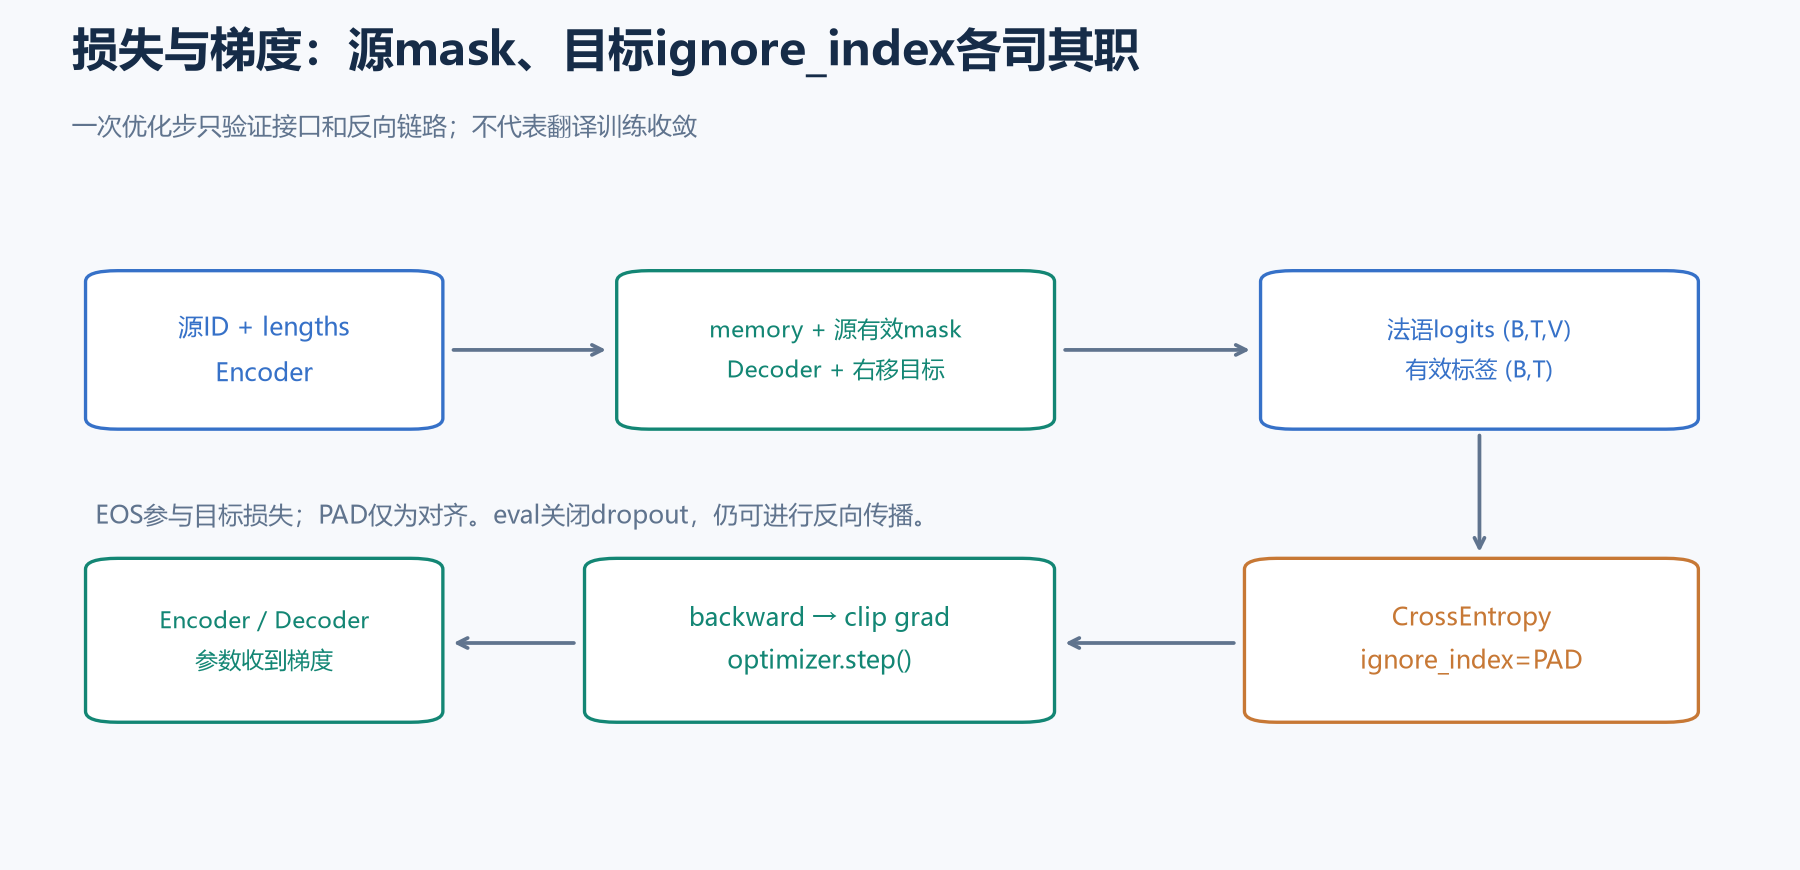

```python
def sequence_loss(logits, targets):
    if logits.shape[:2] != targets.shape:
        raise ValueError("logits的(B,T)必须与target一致")
    if not (targets != PAD).any():
        raise ValueError("没有有效目标token")
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                           ignore_index=PAD)

loss_before = sequence_loss(full_logits, target)
target_used = target != PAD
explicit_loss = F.cross_entropy(full_logits[target_used], target[target_used])
torch.testing.assert_close(loss_before, explicit_loss)
parameters = list(encoder.parameters()) + list(attention_decoder.parameters())
old_parameters = [parameter.detach().clone() for parameter in parameters]
optimizer = torch.optim.SGD(parameters, lr=0.02)
optimizer.zero_grad(set_to_none=True)
loss_before.backward()
for name, module in (("encoder", encoder), ("decoder", attention_decoder),
                     ("attention", attention_decoder.attention)):
    grads = [p.grad for p in module.parameters() if p.requires_grad]
    assert all(g is not None and torch.isfinite(g).all() for g in grads)
    assert sum(g.abs().sum().item() for g in grads) > 0
    print(name, "梯度有限且非零")
gradient_norm = torch.nn.utils.clip_grad_norm_(parameters, max_norm=1.0).item()
optimizer.step()
assert any(not torch.equal(before, after) for before, after in zip(old_parameters, parameters))
with torch.no_grad():
    updated_logits, updated_attention = teacher_forced_forward(
        encoder, attention_decoder, source, lengths, target)
    loss_after = sequence_loss(updated_logits, target)
assert torch.isfinite(loss_after) and loss_after.item() < loss_before.item()
assert torch.all(encoder.embedding.weight[PAD] == 0)
print("有效目标token:", target_used.sum().item(), "更新前/后loss:", loss_before.item(), loss_after.item())
print("裁剪前梯度范数:", gradient_norm)
```

源PAD mask决定“哪些源位置可以被读取”，目标ignore_index决定“哪些词预测参与loss”，两者要分别实现。padding_idx保护PAD嵌入的常规梯度更新，也不能替代packing或注意力mask。

## 22. 如何读模型参数和随机注意力图

GRU有重置、更新、候选三组门参数。单层单向PyTorch GRU输入维E、隐藏维H的参数量是`3H×E + 3H×H + 6H`，最后一项来自两份bias。词表投影层参数是`H×V + V`。

```python
def gru_parameter_count(input_dim, hidden_dim):
    return 3 * hidden_dim * input_dim + 3 * hidden_dim * hidden_dim + 6 * hidden_dim

encoder_expected = len(src_vocab)*EMBED_DIM + gru_parameter_count(EMBED_DIM, HIDDEN_DIM)
plain_expected = (len(tgt_vocab)*EMBED_DIM + gru_parameter_count(EMBED_DIM, HIDDEN_DIM)
                  + HIDDEN_DIM*len(tgt_vocab) + len(tgt_vocab))
parameter_counts = {
    "encoder": sum(p.numel() for p in encoder.parameters()),
    "plain_decoder": sum(p.numel() for p in plain_decoder.parameters()),
    "fixed_decoder": sum(p.numel() for p in fixed_decoder.parameters()),
    "additive_decoder": sum(p.numel() for p in attention_decoder.parameters()),
}
assert parameter_counts["encoder"] == encoder_expected
assert parameter_counts["plain_decoder"] == plain_expected
print("参数量:", parameter_counts)
```

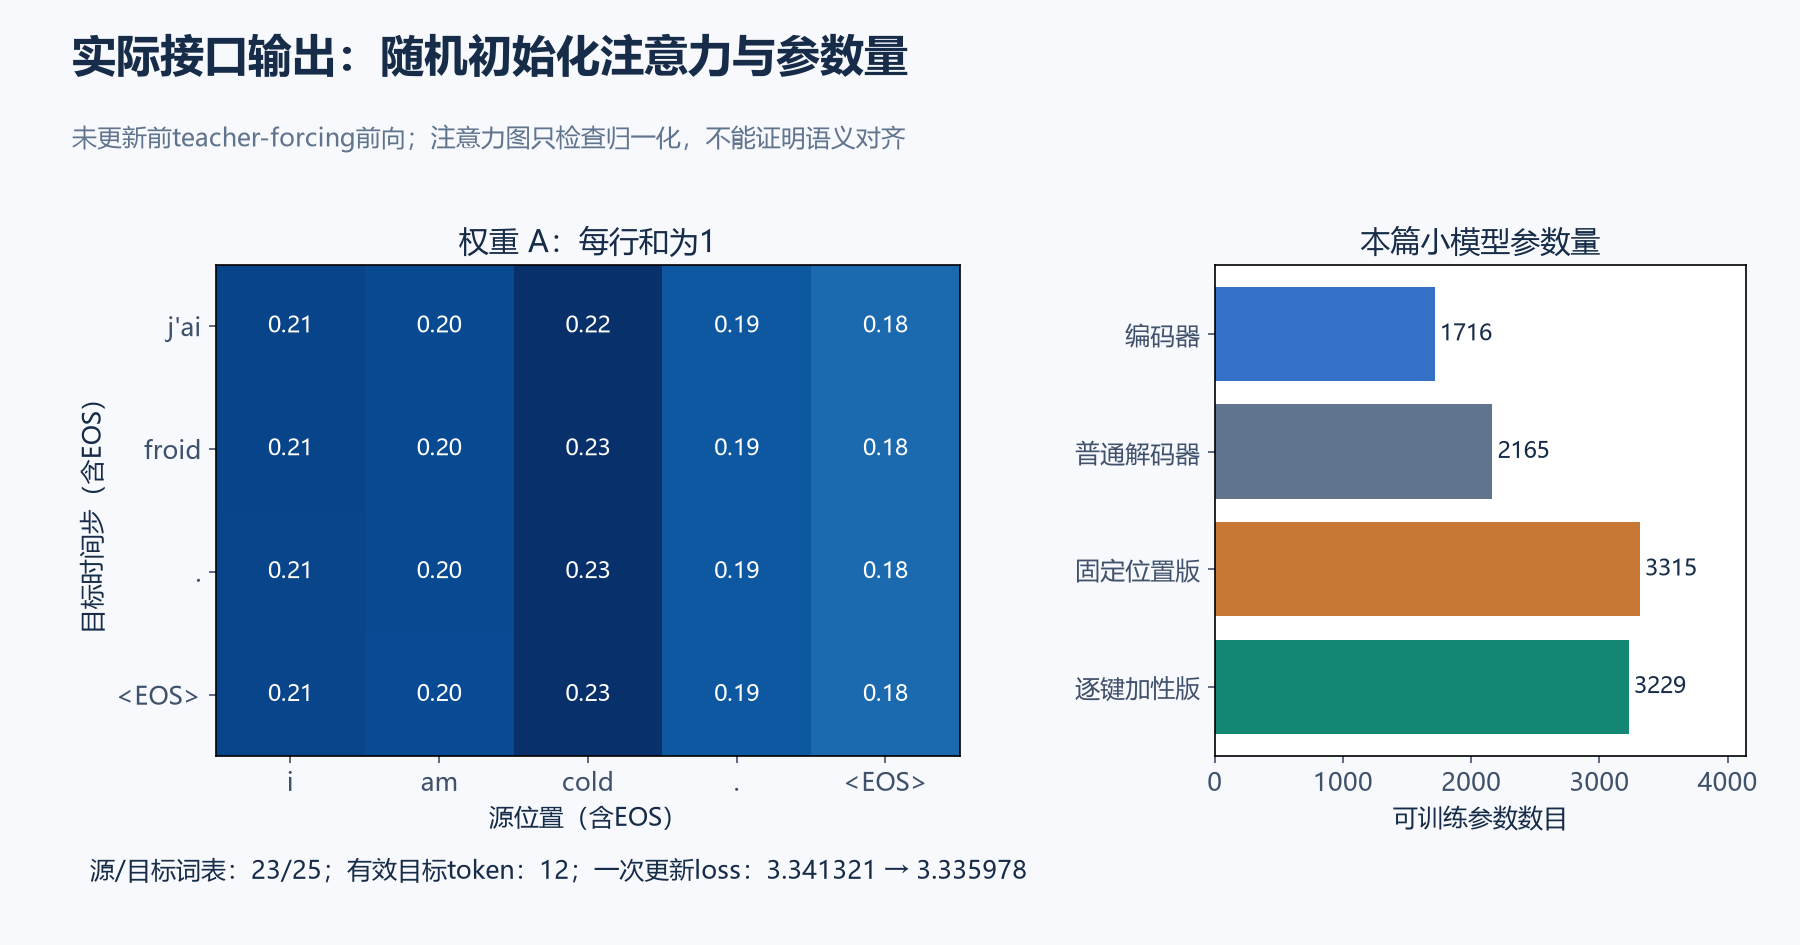

图中权重来自未进行参数更新前的模型，是**随机初始化teacher-forcing前向**；纵轴为目标时间步、横轴为源位置（含EOS），只显示有效目标行和源列。行和为1只能说明归一化正确，不能证明英法对齐或翻译质量。参数更多也不能单独证明模型更好。

## 23. 常见问题与课件注记

| 问题 | 本篇处理 |
| --- | --- |
| ASCII清洗删除法语重音 | 保留Unicode重音和词内撇号；说明教学分词器范围 |
| 课件word2index初始字典写`{0:"SOS",1:"EOS"}` | word→int映射应为字符串key、整数value；混合方向会破坏反向映射 |
| 数据尾部空格与`split(' ')`产生空词 | 使用tokens列表，不把空字符串加入词表 |
| 在Dataset直接创建GPU张量 | Dataset保留CPU，batch取出后统一迁移 |
| batch_size从1改大后stack失败 | 自定义collate，分别PAD两种语言，保留lengths |
| `output[0]`删除真实batch | 保留`(B,T,V)`，单步选择时间轴`[:,0]` |
| GRU读完PAD导致最后hidden不对 | packing跳过右PAD，验证逐条一致 |
| 固定长度10不包含追加EOS | 明确长度上限包含EOS，超长拒绝或预先过滤 |
| encoder_outputs补零后仍分走权重 | Softmax前屏蔽无效源位置 |
| `LogSoftmax`被当普通概率 | 指数才还原概率；按输出配NLL或CE |
| ReLU被描述为能防过拟合 | 只说明其激活作用，正则效果需评估 |
| 随机前向的argmax称为翻译结果 | 本篇只报告接口、梯度与一次更新，不报告翻译准确率 |

课件第31、36页把真实目标token逐个送入decoder，是模型接口测试，不能照搬成“当前位置输入=当前位置标签”的训练。正式训练应从SOS开始，使用右移真实词或上一轮预测。

课件从第41页继续讲完整训练与预测，本篇在线阅读它们是为核对上下文，day06笔记主线仍是第1–40页与16节视频的内容。

## 24. 练习与参考答案

1. **英文和法文为什么要分两个词表？** 两侧词集合与ID含义不同；encoder embedding查英文表，decoder embedding和输出分类使用法文表。
2. **SOS/EOS/PAD分别在哪里出现？** SOS是decoder首输入；EOS标记句子结束且是预测标签；PAD用于批次对齐，不参加目标loss。
3. **源batch=`(4,8)`、H=32，encoder输出shape是什么？** memory=`(4,8,32)`，单层单向hidden=`(1,4,32)`。
4. **batch_first是否让hidden变成`(B,1,H)`？** 不会，hidden布局始终按层/方向在前。
5. **PAD embedding为零为什么还要packing？** GRU存在递推与bias，读入零也会更新状态；packing保证最后hidden对应真实长度。
6. **法语目标`[je,suis,EOS]`的teacher-forcing输入是什么？** `[SOS,je,suis]`。
7. **目标长度5、源长度8、batch4，注意力矩阵shape是什么？** 堆叠后`(4,5,8)`，每个目标步沿8个源位置归一化。
8. **注意力权重能直接作为下一法文ID吗？** 不能，其索引是源位置；词预测来自法语词表logits。
9. **固定位置注意力改用15个位置如何处理？** 重建相应固定输出层并核对旧参数兼容性；逐键版可复用打分参数，但输入与mask仍要匹配。
10. **一次优化步loss下降证明了什么？** 数据、模型、损失和梯度路径可运行；不能证明收敛、自由生成或泛化。
11. **CUDA是否可用该看哪个数值？** 先看PyTorch是否为支持CUDA的构建与设备可见性，再运行实际CUDA张量运算；不能只看nvidia-smi版本行。
12. **训练词表为什么不能从全部句对建？** 会把留出数据的信息带入预处理；真实评估应先划分，再拟合词表或分词器。

## 25. 实际验证记录

验证日期：2026-10-13。Python 3.12.13、NumPy 1.26.4、PyTorch 2.14.1+cpu，CPU，随机种子2026。GPU分支未运行。

| 验证项 | 实际结果 |
| --- | --- |
| Python代码块 | 18段按顺序全部运行通过 |
| 句对读取 | 自编12对；缺TAB、额外列、空字段均拒绝 |
| Unicode规范化 | 重音、组合字符、词内撇号与标点样例通过 |
| 数据与词表 | train/dev/test=8/2/2，源句分组不重叠；只用train建英语/法语词表，大小23/25 |
| Dataset与collate | CPU long、EOS、越界拒绝、右PAD、尾批3/3/2均通过 |
| 目标右移 | SOS首输入与前一步真实词对应，EOS参与标签 |
| GRU编码 | memory=(3, 5, 16)，hidden=(1, 3, 16) |
| 编码器等价 | packed/逐条/逐步通过；整句与逐步最大误差`5.960e-08`；额外右PAD无影响 |
| 普通解码器 | logits=(3, 1, 25)；CE与LogSoftmax+NLL一致 |
| 固定位置Attention | batch=3，权重(3,10)；PAD权重为0；11位置明确拒绝 |
| 逐键Attention | 权重(3,5)；逐条/批量、改PAD内容、额外PAD检查通过 |
| 完整teacher-forcing前向 | logits=(3, 5, 25)，attention=(3, 5, 5) |
| 一次参数更新 | 有效目标token=12；CE `3.341321` → `3.335978`；梯度有限且参数更新 |
| 裁剪前梯度范数 | `0.517240` |
| 模型参数量 | 编码器1716，普通decoder 2165，固定位置版3315，逐键版3229 |
| 既有文件 | 55本笔记SHA256保持一致 |


全部Python代码块在同一环境中按顺序运行。数值可能随PyTorch版本略有变化，重点检查shape、有效位置、不变量与有限梯度。本篇没有加载课件训练权重，也没有开展翻译质量评测。

## 26. 资料与复习路径

课程资料：[NLP百度网盘分享](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码`1234`；对应`03-视频/day06`16节、《07-案例Seq2Seq英译法案例.pdf》第1–40页。CUDA安装参考：[PyTorch官方安装选择器](https://pytorch.org/get-started/locally/)。

进一步查阅：[Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html)、[GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)、[DataLoader](https://docs.pytorch.org/docs/stable/data.html)、[pack_padded_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html)、[CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)。API链接供后续查阅，不表示本篇逐页核对了所有版本文档。

复习顺序：先解释特殊token与两侧词表，再手写一个变长batch和右移目标；随后核对encoder的memory/hidden，最后比较三种decoder输出与注意力轴。能从原始句对一路追踪到目标loss，就具备继续写完整训练循环的基础。